# Sales Dynamics and Seasonality

This notebook looks at how total retail sales change over time. The goal is to identify practical patterns that may help with inventory planning.

## 1. Load the data

The sales file stores one product-store combination per row and one day per column. The calendar file maps technical day IDs such as `d_1` to real dates.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

sales_path = "data/raw/sales_train_validation.csv"
calendar_path = "data/raw/calendar.csv"

sales = pd.read_csv(sales_path)
calendar = pd.read_csv(calendar_path)
day_columns = [column for column in sales.columns if column.startswith("d_")]

print(f"Sales rows: {sales.shape[0]:,}")
print(f"Days available: {len(day_columns):,}")

Sales rows: 30,490
Days available: 1,913


## 2. Calculate total sales by day

I sum unit sales across all products and stores. This gives one total demand value for each day.

In [2]:
daily_sales = sales[day_columns].sum(axis=0).rename("units_sold").reset_index()
daily_sales = daily_sales.rename(columns={"index": "d"})
daily_sales = daily_sales.merge(calendar[["d", "date", "weekday", "month", "year"]], on="d", how="left")
daily_sales["date"] = pd.to_datetime(daily_sales["date"])
daily_sales.head()

,d,units_sold,date,weekday,month,year
0,d_1,32631,2011-01-29,Saturday,1,2011
1,d_2,31749,2011-01-30,Sunday,1,2011
2,d_3,23783,2011-01-31,Monday,1,2011
3,d_4,25412,2011-02-01,Tuesday,2,2011
4,d_5,19146,2011-02-02,Wednesday,2,2011


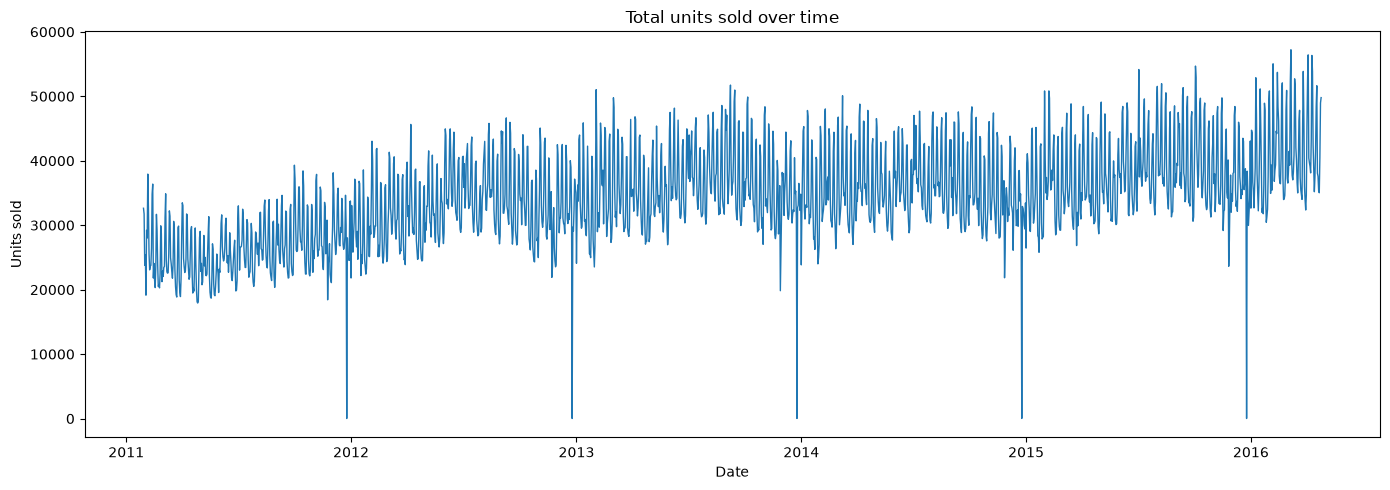

In [3]:
plt.figure(figsize=(14, 5))
plt.plot(daily_sales["date"], daily_sales["units_sold"], linewidth=1)
plt.title("Total units sold over time")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.tight_layout()
plt.show()

The daily series shows recurring fluctuations rather than a perfectly stable level of demand. This suggests that inventory planning should account for time-related patterns instead of using one overall average.

## 3. Compare average sales by weekday

Weekday patterns can help stores plan staffing, replenishment and shelf availability.

In [4]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_summary = (
    daily_sales.groupby("weekday", as_index=False)["units_sold"]
    .mean()
    .assign(weekday=lambda frame: pd.Categorical(frame["weekday"], categories=weekday_order, ordered=True))
    .sort_values("weekday")
)
weekday_summary

,weekday,units_sold
1,Monday,32852.967033
5,Tuesday,30368.780220
6,Wednesday,30010.021978
4,Thursday,30205.007326
0,Friday,34225.985348
2,Saturday,41546.894161
3,Sunday,41130.021898


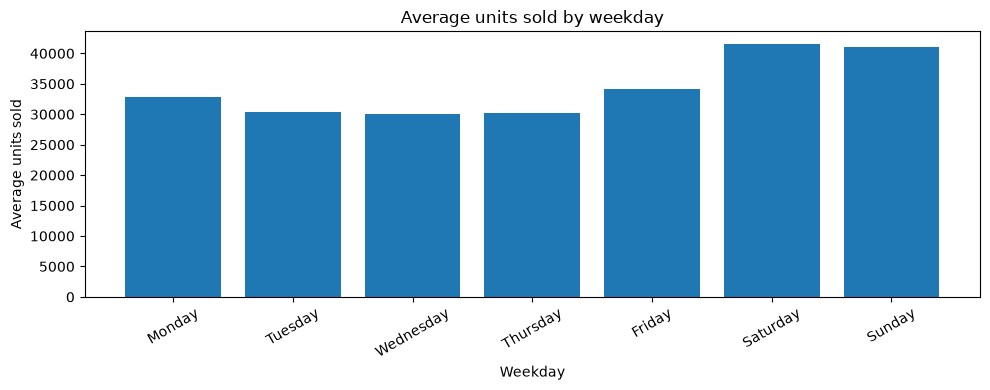

In [5]:
plt.figure(figsize=(10, 4))
plt.bar(weekday_summary["weekday"], weekday_summary["units_sold"])
plt.title("Average units sold by weekday")
plt.xlabel("Weekday")
plt.ylabel("Average units sold")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 4. Compare average sales by month

Monthly averages help reveal recurring seasonal differences across the year.

In [6]:
monthly_summary = daily_sales.groupby("month", as_index=False)["units_sold"].mean()
monthly_summary = monthly_summary.sort_values("month")
monthly_summary

,month,units_sold
0,1,33832.348101
1,2,34644.641176
2,3,34339.838710
3,4,34258.683908
4,5,32503.851613
5,6,35001.413333
6,7,35122.419355
7,8,35946.645161
8,9,35479.260000
9,10,34713.477419


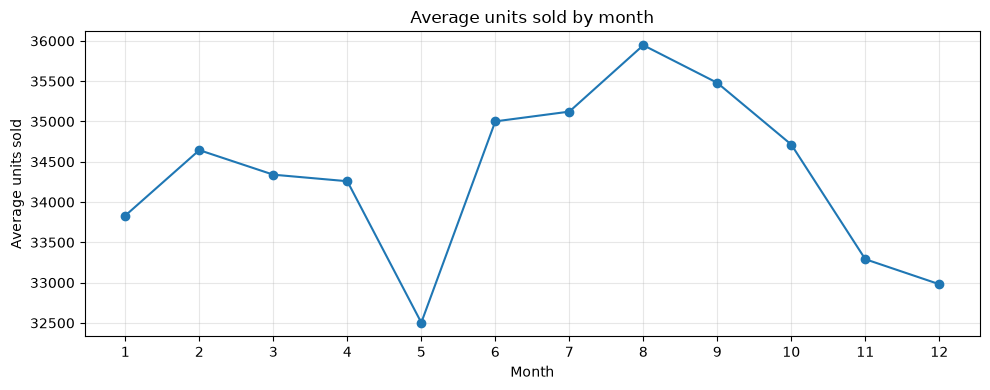

In [7]:
plt.figure(figsize=(10, 4))
plt.plot(monthly_summary["month"], monthly_summary["units_sold"], marker="o")
plt.title("Average units sold by month")
plt.xlabel("Month")
plt.ylabel("Average units sold")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Business takeaway

Sales vary across days of the week and months, so a single average is not enough for inventory planning. A practical next step would be to use store- and category-level patterns when setting replenishment priorities and reviewing seasonal stock needs.